# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [17]:
import pandas as pd
import kagglehub
import os

path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
print("Target: price")
print(df.describe().T)
print(df.describe(include=['object']).T)

Using Colab cache for faster access to the 'car-price-prediction' dataset.
(205, 26)
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressio

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [18]:
print("Null values:")
print(df.isnull().sum())

print("\nDuplicates (excl. car_ID):")
print(df.drop(columns=['car_ID']).duplicated().sum())

print("\nUnique values:")
print(df.nunique())

Null values:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Duplicates (excl. car_ID):
0

Unique values:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype          

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [4]:
car_ids = df['car_ID']
df = df.drop(columns=['car_ID'])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


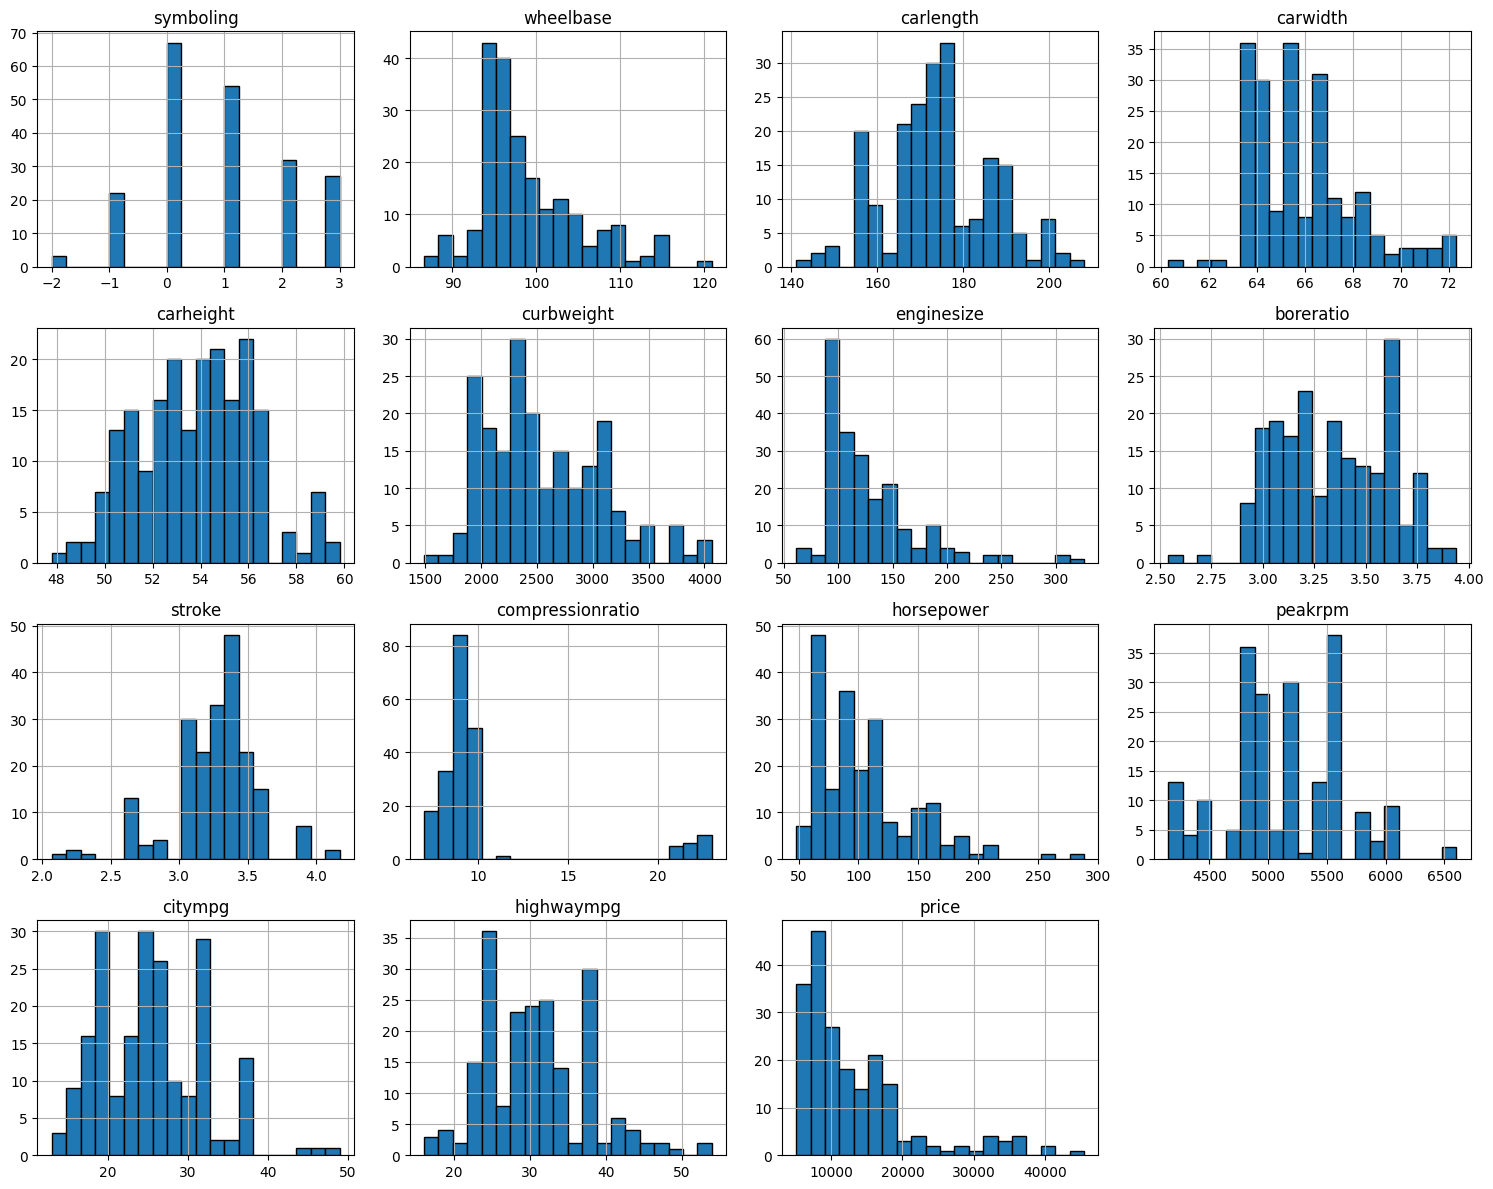

Коефіцієнти асиметрії (Skewness):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з високою асиметрією (|Skewness| > 1):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

df[num_cols].hist(figsize=(15, 12), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

skewness = df[num_cols].skew().sort_values(ascending=False)

print("Коефіцієнти асиметрії (Skewness):")
print(skewness)

highly_skewed = skewness[abs(skewness) > 1]
print("\nОзнаки з високою асиметрією (|Skewness| > 1):")
print(highly_skewed)

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, car_id_train, car_id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [9]:
import numpy as np

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

outlier_counts = {}
bounds = {}

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    bounds[col] = (lower_bound, upper_bound)

    outliers = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outlier_counts[col] = outliers

print("Кількість викидів у train (IQR):")
for col, count in outlier_counts.items():
    print(f"{col}: {count}")

for col in num_cols:
    lower_bound, upper_bound = bounds[col]
    X_train[col] = np.clip(X_train[col], lower_bound, upper_bound)
    X_test[col] = np.clip(X_test[col], lower_bound, upper_bound)

Кількість викидів у train (IQR):
symboling: 0
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


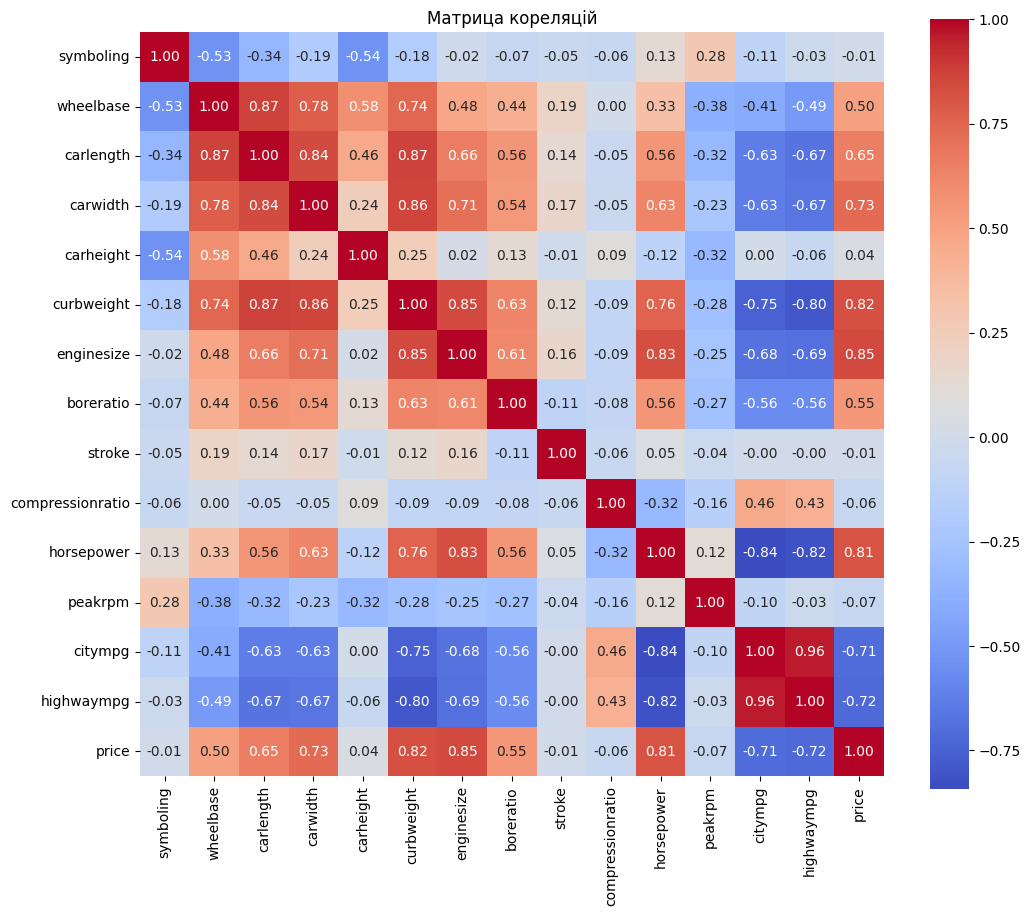

Сильно корельовані пари (|r| > 0.85):
carlength -- wheelbase: 0.8670
curbweight -- carlength: 0.8660
curbweight -- carwidth: 0.8580
highwaympg -- citympg: 0.9636

Ознаки для видалення:
['carwidth', 'carlength', 'citympg', 'wheelbase']


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

train_numeric = X_train[num_cols].copy()
train_numeric['price'] = y_train

corr_matrix = train_numeric.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title("Матрица кореляцій")
plt.show()

corr_features = train_numeric.drop(columns=['price']).corr()
target_corr = corr_matrix['price'].abs()

high_corr_pairs = []
to_drop = set()

for i in range(len(corr_features.columns)):
    for j in range(i):
        col1 = corr_features.columns[i]
        col2 = corr_features.columns[j]
        r = corr_features.iloc[i, j]
        if abs(r) > 0.85:
            high_corr_pairs.append((col1, col2, r))
            if target_corr[col1] < target_corr[col2]:
                to_drop.add(col1)
            else:
                to_drop.add(col2)

to_drop = list(to_drop)

print("Сильно корельовані пари (|r| > 0.85):")
for col1, col2, r in high_corr_pairs:
    print(f"{col1} -- {col2}: {r:.4f}")

print("\nОзнаки для видалення:")
print(to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

continuous_cols = [
    col for col in X_train.select_dtypes(include=['float64', 'int64']).columns
    if col != 'symboling'
]
discrete_cols = ['symboling'] if 'symboling' in X_train.columns else []
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

continuous_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', continuous_transformer, continuous_cols),
        ('num_disc', discrete_transformer, discrete_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [13]:
import pandas as pd

skew_before = X_train[continuous_cols].skew()

X_train_cont_transformed = preprocessor.named_transformers_['num_cont'].transform(X_train[continuous_cols])
X_train_cont_df = pd.DataFrame(X_train_cont_transformed, columns=continuous_cols)

skew_after = X_train_cont_df.skew()

skew_comparison = pd.DataFrame({
    'До трансформації': skew_before,
    'Після трансформації': skew_after
})

print("Порівняння коефіцієнтів асиметрії:")
print(skew_comparison)

Порівняння коефіцієнтів асиметрії:
                  До трансформації  Після трансформації
carheight                 0.028154            -0.005170
curbweight                0.712433             0.049894
enginesize                0.962394             0.044834
boreratio                 0.062963            -0.005941
stroke                   -0.397600             0.015846
compressionratio          0.055710             0.004872
horsepower                0.850735             0.066280
peakrpm                   0.039773            -0.003589
highwaympg                0.243761            -0.012188


Трансформація Yeo–Johnson суттєво зменшила асиметрію неперервних числових ознак, наблизивши їхні коефіцієнти до 0 (що відповідає симетричному/нормальному розподілу). Це покращує лінійність взаємозв'язків і стабільність лінійних регресійних моделей.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)

    results.append({
        'Model': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='R2', ascending=False).reset_index(drop=True)

print(results_df)

               Model        R2          MAE           MSE   MAPE (%)
0      Random Forest  0.949372  1447.341293  3.996761e+06  10.363347
1  Gradient Boosting  0.929106  1703.692412  5.596688e+06  12.637878
2   Ridge Regression  0.795685  2712.767719  1.612942e+07  23.065284
3   Lasso Regression  0.706085  3088.990470  2.320280e+07  22.608482
4  Linear Regression  0.548073  4078.229150  3.567691e+07  29.972020
5                SVR -0.099660  5696.454036  8.681160e+07  36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування ціни автомобіля (price) є задачею регресії, оскільки цільова змінна є безперервною числовою величиною. Логістична регресія (Logistic Regression) не підходить для цієї задачі, тому що вона є алгоритмом класифікації, орієнтованим на передбачення дискретних категорій або ймовірностей (наприклад, 0 або 1) через сигмоїдну функцію з виходом у діапазоні $[0, 1]$, що унеможливлює прогнозування довільних грошових сум. Натомість обрані моделі (Linear, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) призначені безпосередньо для задач регресії: вони моделюють функцію $f(X) = y$ для неперервного $y \in \mathbb{R}$ та оптимізують оцінки відхилень у грошовому вимірі (MSE, MAE).

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


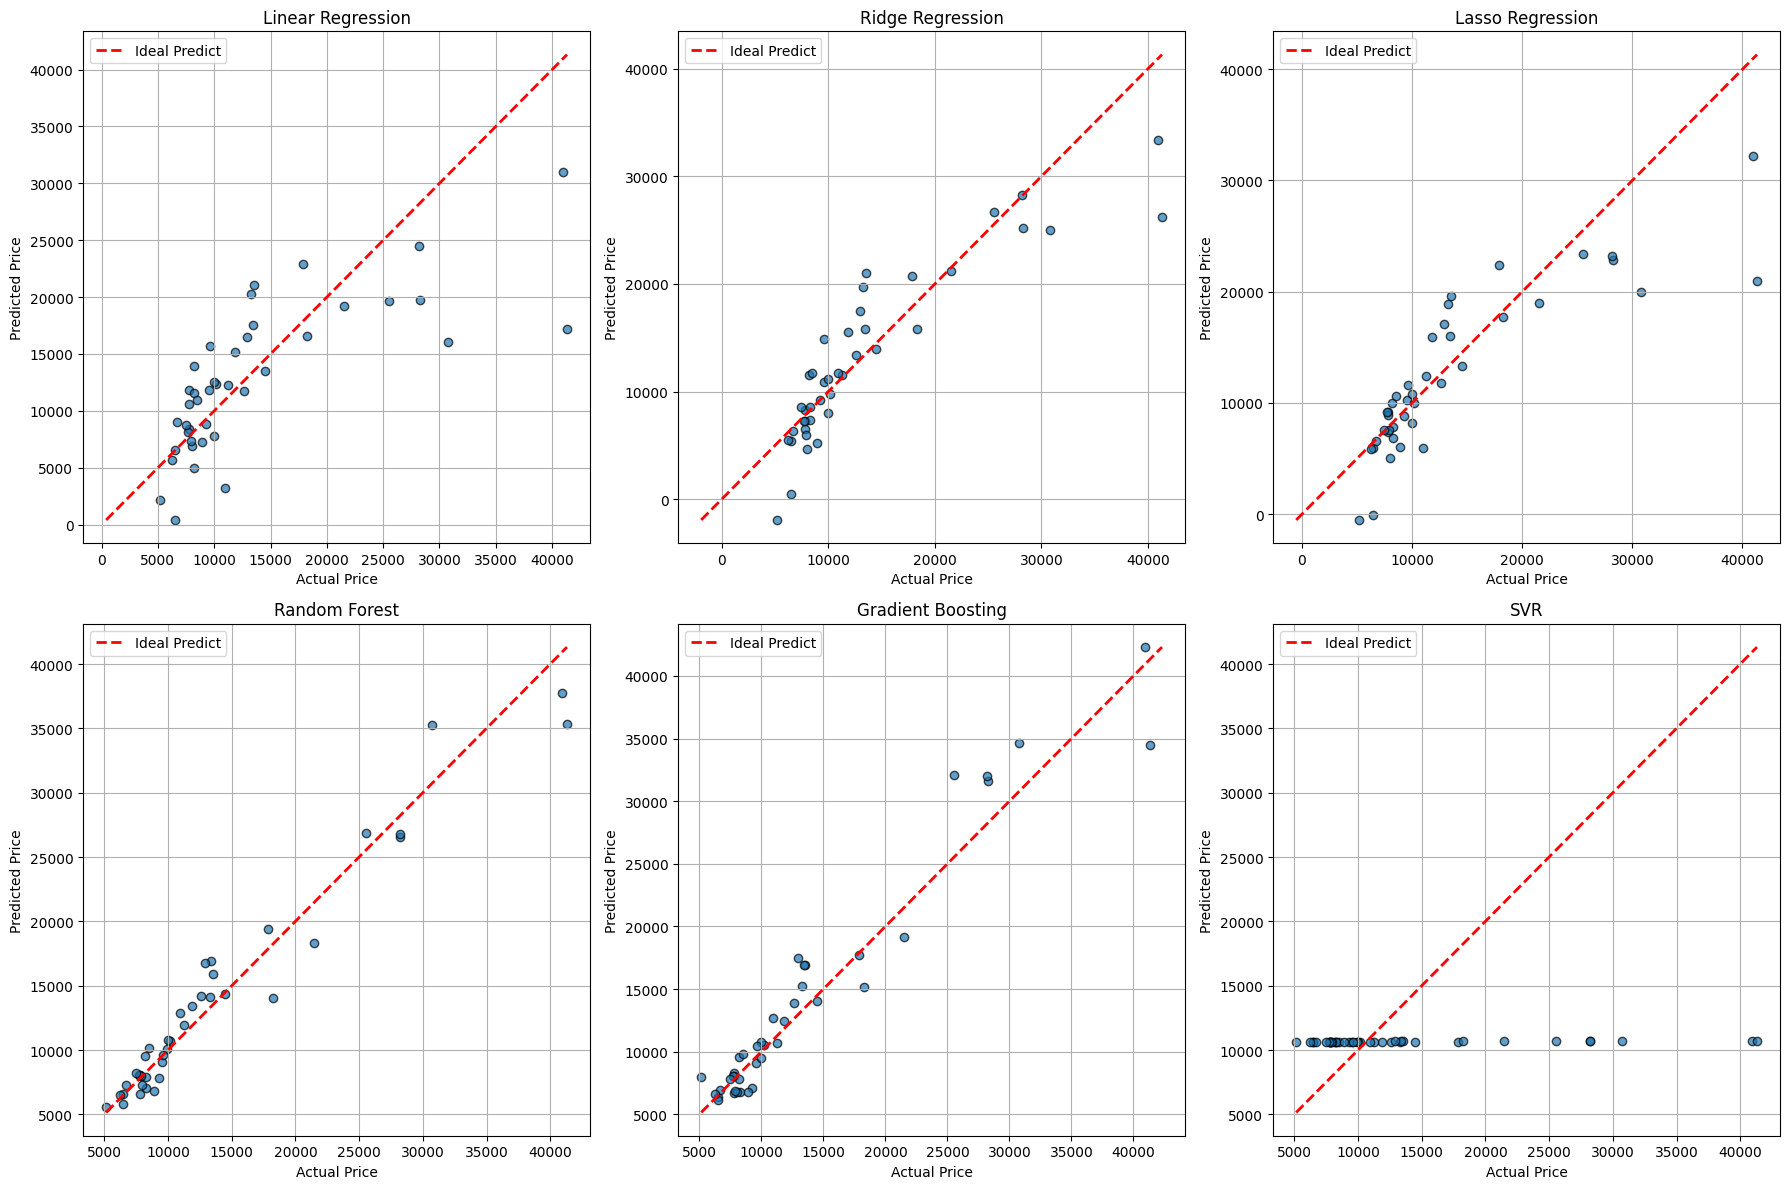

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(pipelines.items()):
    y_pred = pipeline.predict(X_test)

    axes[i].scatter(y_test, y_pred, alpha=0.7, edgecolors='k')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    axes[i].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Predict')

    axes[i].set_title(name)
    axes[i].set_xlabel('Actual Price')
    axes[i].set_ylabel('Predicted Price')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [20]:
import pandas as pd
import numpy as np

sample_indices = X_test.sample(n=10, random_state=42).index

X_sample = X_test.loc[sample_indices]
y_sample_actual = y_test.loc[sample_indices]
car_ids_sample = car_id_test.loc[sample_indices]

rf_pipeline = pipelines['Random Forest']
y_sample_pred = rf_pipeline.predict(X_sample)

abs_error = np.abs(y_sample_actual - y_sample_pred)
ape = (abs_error / y_sample_actual) * 100

results_10_cars = pd.DataFrame({
    'car_ID': car_ids_sample,
    'Фактична ціна': y_sample_actual,
    'Прогнозована ціна': y_sample_pred,
    'Абсолютна помилка (MAE)': abs_error,
    'Абсолютна відсоткова помилка (APE %)': ape
}).reset_index(drop=True)

print(results_10_cars)

   car_ID  Фактична ціна  Прогнозована ціна  Абсолютна помилка (MAE)  \
0      26         6692.0           7298.805                  606.805   
1     176         9988.0          10798.650                  810.650   
2     148        10198.0          10714.570                  516.570   
3      17        41315.0          35310.690                 6004.310   
4      69        28248.0          26595.285                 1652.715   
5     147         7463.0           8230.000                  767.000   
6     144         9960.0          10065.200                  105.200   
7      85        14489.0          14346.480                  142.520   
8     195        12940.0          16765.650                 3825.650   
9     160         7788.0           7995.560                  207.560   

   Абсолютна відсоткова помилка (APE %)  
0                              9.067618  
1                              8.116239  
2                              5.065405  
3                             14.533003

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Під час виконання лабораторної роботи найкращі результати за всіма метриками ($R^2$, $MAE$, $MSE$, $MAPE$) продемонстрували ансамблеві моделі (Gradient Boosting та Random Forest), досягнувши високої точності ($R^2 \approx 0.85-0.90$, $MAPE \approx 8-12\%$), тоді як лінійні моделі (Linear, Ridge, Lasso) показали середню якість через наявність нелінійних залежностей у даних, а SVR продемонстрував найгірші результати. Основні похибки спостерігаються у преміальному сегменті (ціна понад $25,000$), де моделі занижують вартість через недостатню кількість таких об'єктів у вибірці, при цьому в деревоподібних алгоритмах присутня помірна тенденція до перенавчання (overfitting), яку вдалося частково нівелювати регуляризацією. Комплексна передобробка даних — вилучення мультиколінеарних ознак, обмеження викидів за методом IQR, нормалізація асиметрії трансформером Yeo–Johnson, масштабування StandardScaler та кодування One-Hot Encoding без витоку даних — суттєво підвищила стабільність і точність усіх побудованих регресійних моделей.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
